In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


In [ ]:
df=pd.read_csv('restaurant_raw_dataset_for_apriori.csv')

In [ ]:
df.head()

,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,received_by,time_of_sale
0,ORD0001,2026-01-01,Burger,Main Course,149,1,386,Takeaway,Cashier,20:40
1,ORD0001,2026-01-01,French Fries,Side,89,1,386,Takeaway,Cashier,20:40
2,ORD0001,2026-01-01,Coca-Cola,Beverage,49,1,386,Takeaway,Cashier,20:40
3,ORD0001,2026-01-01,Chocolate Brownie,Dessert,99,1,386,Takeaway,Cashier,20:40
4,ORD0002,2026-01-02,Burger,Main Course,149,1,376,Dine-in,Waiter,15:45


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   order_id            1000 non-null   object
 1   date                1000 non-null   object
 2   item_name           1000 non-null   object
 3   item_type           1000 non-null   object
 4   item_price          1000 non-null   int64 
 5   quantity            1000 non-null   int64 
 6   transaction_amount  1000 non-null   int64 
 7   transaction_type    1000 non-null   object
 8   received_by         1000 non-null   object
 9   time_of_sale        1000 non-null   object
dtypes: int64(3), object(7)
memory usage: 78.3+ KB


In [ ]:
df.shape

(1000, 10)

In [ ]:
df.isnull().sum()

,0
order_id,0
date,0
item_name,0
item_type,0
item_price,0
quantity,0
transaction_amount,0
transaction_type,0
received_by,0
time_of_sale,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.drop(['date', 'item_type', 'item_price', 'quantity',
     'transaction_amount', 'transaction_type',
     'received_by', 'time_of_sale'],axis=1,inplace=True)

In [ ]:
df['item_name'].unique()

array(['Burger', 'French Fries', 'Coca-Cola', 'Chocolate Brownie',
       'Vanilla Ice Cream', 'Onion Rings', 'Mineral Water',
       'Cheeseburger', 'Pepsi', 'Chocolate Cake', 'Chicken Burger',
       'Chocolate Milkshake', 'Margherita Pizza', 'Garlic Bread',
       'Veg Sandwich', 'Lemonade', 'Cheesecake', 'Pasta Alfredo',
       'Iced Tea', 'Club Sandwich', 'Chicken Wrap', 'Farmhouse Pizza',
       'Chicken Nuggets', 'Hot Dog'], dtype=object)

In [ ]:
df['item_name']=df['item_name'].str.strip()

In [ ]:
df['item_name']=df['item_name'].str.lower()

In [ ]:
print(df['item_name'])

0                 burger
1           french fries
2              coca-cola
3      chocolate brownie
4                 burger
             ...        
995            coca-cola
996              hot dog
997          onion rings
998        mineral water
999       chocolate cake
Name: item_name, Length: 1000, dtype: object


In [ ]:
df['item_name'].unique()

array(['burger', 'french fries', 'coca-cola', 'chocolate brownie',
       'vanilla ice cream', 'onion rings', 'mineral water',
       'cheeseburger', 'pepsi', 'chocolate cake', 'chicken burger',
       'chocolate milkshake', 'margherita pizza', 'garlic bread',
       'veg sandwich', 'lemonade', 'cheesecake', 'pasta alfredo',
       'iced tea', 'club sandwich', 'chicken wrap', 'farmhouse pizza',
       'chicken nuggets', 'hot dog'], dtype=object)

In [ ]:
transactions=df.groupby('order_id')['item_name'].apply(list).tolist()

In [ ]:
print(transactions[:5])

[['burger', 'french fries', 'coca-cola', 'chocolate brownie'], ['burger', 'french fries', 'coca-cola', 'vanilla ice cream'], ['burger', 'french fries', 'coca-cola', 'onion rings'], ['burger', 'french fries', 'coca-cola', 'mineral water'], ['burger', 'french fries', 'coca-cola', 'chocolate brownie']]


In [ ]:
from mlxtend.preprocessing import TransactionEncoder
te=TransactionEncoder()
df_array=te.fit(transactions).transform(transactions)

In [ ]:
df_array.head()

AttributeError: 'numpy.ndarray' object has no attribute 'head'

In [ ]:
df_encoded=pd.DataFrame(df_array,columns=te.columns_)

In [ ]:
print(df_encoded.head())

   burger  cheeseburger  cheesecake  chicken burger  chicken nuggets  \
0    True         False       False           False            False   
1    True         False       False           False            False   
2    True         False       False           False            False   
3    True         False       False           False            False   
4    True         False       False           False            False   

   chicken wrap  chocolate brownie  chocolate cake  chocolate milkshake  \
0         False               True           False                False   
1         False              False           False                False   
2         False              False           False                False   
3         False              False           False                False   
4         False               True           False                False   

   club sandwich  ...  hot dog  iced tea  lemonade  margherita pizza  \
0          False  ...    False     False    

In [ ]:
from mlxtend.frequent_patterns import apriori
frequent_itemsets=apriori(df_encoded,min_support=0.3,use_colnames=True)

In [ ]:
print(frequent_itemsets.head())

   support                itemsets
0    0.400                (burger)
1    0.584             (coca-cola)
2    0.768          (french fries)
3    0.400     (coca-cola, burger)
4    0.400  (french fries, burger)


In [ ]:
frequent_itemsets=frequent_itemsets.sort_values(by='support',ascending=False)

In [ ]:
from mlxtend.frequent_patterns import association_rules

In [ ]:
rules=association_rules(frequent_itemsets,metric='confidence',min_threshold=0.50)

In [ ]:
print(rules)

                  antecedents                consequents  antecedent support  \
0                 (coca-cola)             (french fries)               0.584   
1              (french fries)                (coca-cola)               0.768   
2                 (coca-cola)                   (burger)               0.584   
3                    (burger)                (coca-cola)               0.400   
4              (french fries)                   (burger)               0.768   
5                    (burger)             (french fries)               0.400   
6   (coca-cola, french fries)                   (burger)               0.504   
7         (coca-cola, burger)             (french fries)               0.400   
8      (french fries, burger)                (coca-cola)               0.400   
9                 (coca-cola)     (french fries, burger)               0.584   
10             (french fries)        (coca-cola, burger)               0.768   
11                   (burger)  (coca-col

In [ ]:
rules = rules.sort_values(
    by='confidence',
    ascending=False
)

In [ ]:
rules[['antecedents', 'consequents',
       'support', 'confidence', 'lift']]

,antecedents,consequents,support,confidence,lift
3,(burger),(coca-cola),0.400,1.000000,1.712329
11,(burger),"(coca-cola, french fries)",0.400,1.000000,1.984127
7,"(coca-cola, burger)",(french fries),0.400,1.000000,1.302083
5,(burger),(french fries),0.400,1.000000,1.302083
8,"(french fries, burger)",(coca-cola),0.400,1.000000,1.712329
0,(coca-cola),(french fries),0.504,0.863014,1.123716
6,"(coca-cola, french fries)",(burger),0.400,0.793651,1.984127
2,(coca-cola),(burger),0.400,0.684932,1.712329
9,(coca-cola),"(french fries, burger)",0.400,0.684932,1.712329
1,(french fries),(coca-cola),0.504,0.656250,1.123716


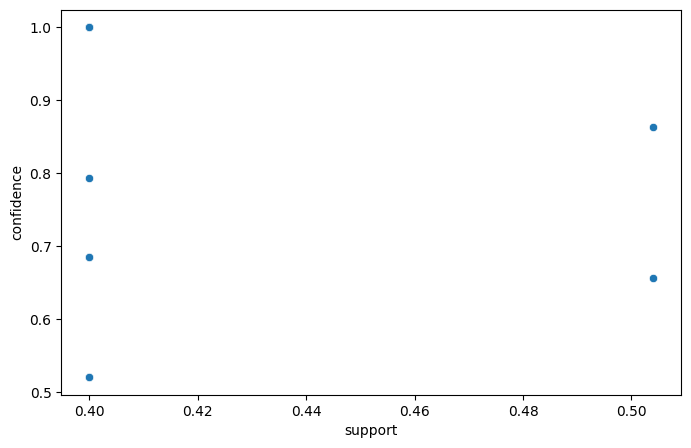

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(data=rules, x='support', y='confidence')

plt.show()